# Modeling MLB Game Outcomes vs. the Betting Market

Can a model built from public game logs and closing odds predict MLB winners better than simply backing the betting favorite?

**Data:** Retrosheet game logs merged with closing sportsbook odds, 2012–2016 regular seasons (see `data/README.md`).
**Questions:**
1. Why is the MLB run line almost always ±1.5?
2. Which pre-game features best predict outcomes and margins?
3. Does a Random Forest beat a dummy baseline and the market favorite?

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, brier_score_loss,
                             confusion_matrix, log_loss, mean_absolute_error, r2_score)
from sklearn.model_selection import GroupShuffleSplit

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from mlb_outcomes.data import load_dataset
from mlb_outcomes.features import build_features

DATA = ROOT / "data" / "raw"
FIGS = ROOT / "figures"
RESULTS = ROOT / "results"
FIGS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="talk")

def savefig(name):
    plt.savefig(FIGS / name, dpi=150, bbox_inches="tight")

## 1. Load and merge

Game logs and odds are joined on date, teams **and final score**, so each game in a doubleheader gets its own closing line. Moneylines are converted to implied probabilities and the bookmaker's margin (overround) is removed.

In [2]:
df = load_dataset(DATA / "game_logs.csv", DATA / "oddsDataMLB.csv")
df = build_features(df)
print(f"{len(df):,} games, {df['date'].min().date()} to {df['date'].max().date()}")
print(f"{df[['home_prob', 'away_prob']].notna().all(axis=1).sum():,} matched to closing odds")

12,148 games, 2012-03-28 to 2016-10-02
12,146 matched to closing odds


## 2. Q1 — Why is the spread ±1.5?

In [3]:
an = df.dropna(subset=['abs_margin','closing_total','home_prob','away_prob']).copy()

p_le1 = (an['abs_margin'] <= 1).mean()
p_ge2 = (an['abs_margin'] >= 2).mean()
print(f"% decided by 1 run:   {p_le1:.3f}")
print(f"% decided by ≥2 runs: {p_ge2:.3f}")

X_lin = an[['closing_total','fav_edge']].to_numpy()
y_lin = an['abs_margin'].to_numpy()
lin = LinearRegression().fit(X_lin, y_lin)
print("\n|margin| ~ closing_total + fav_edge")
print("  coefs [total, edge]:", lin.coef_.round(3), " intercept:", round(lin.intercept_, 3),
      " R²:", round(lin.score(X_lin, y_lin), 3))

% decided by 1 run:   0.295
% decided by ≥2 runs: 0.705

|margin| ~ closing_total + fav_edge
  coefs [total, edge]: [0.174 0.669]  intercept: 1.844  R²: 0.005


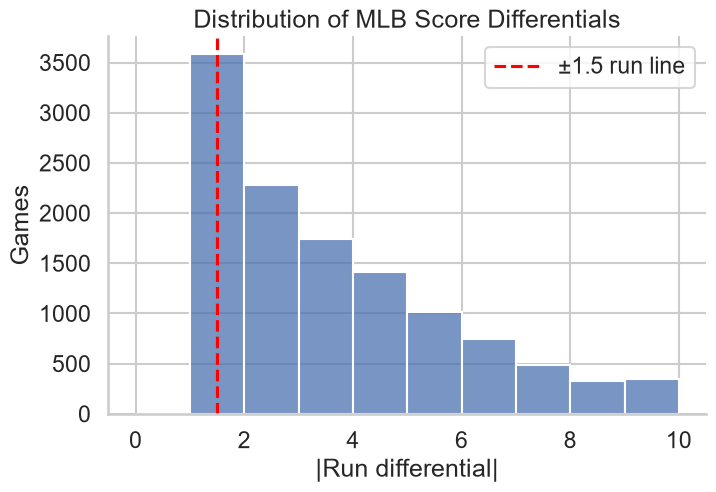

In [4]:
sns.displot(data=an, x="abs_margin", bins=range(0, 11), kde=False, height=5, aspect=1.5)
plt.axvline(1.5, color="red", linestyle="--", label="±1.5 run line")
plt.title("Distribution of MLB Score Differentials")
plt.xlabel("|Run differential|"); plt.ylabel("Games"); plt.legend()
savefig("margin_distribution.png"); plt.show()

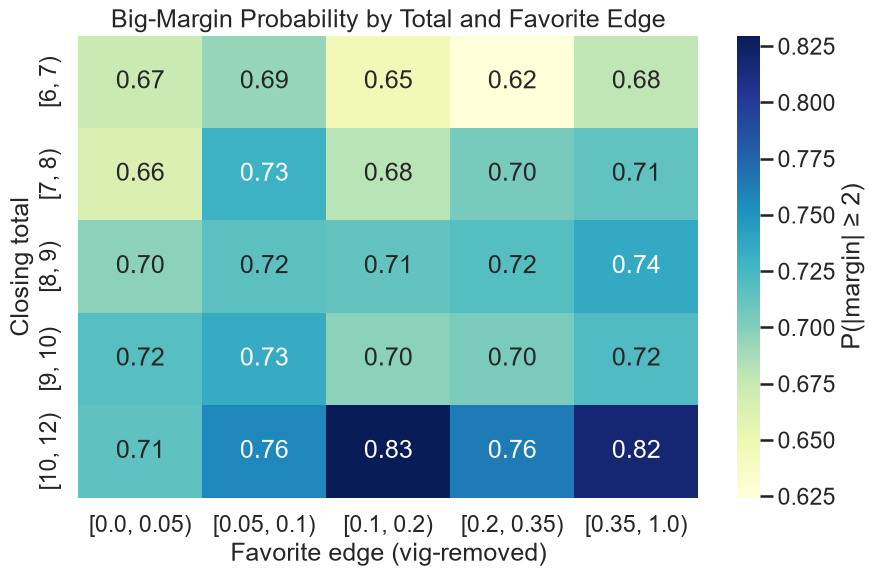

In [5]:
an['total_bin'] = pd.cut(an['closing_total'], bins=[6,7,8,9,10,12], right=False)
an['edge_bin']  = pd.cut(an['fav_edge'], bins=[0,0.05,0.10,0.20,0.35,1.0], right=False)
heat = (an.groupby(['total_bin','edge_bin'], observed=False)['abs_margin']
          .apply(lambda s: (s >= 2).mean()).unstack('edge_bin'))
plt.figure(figsize=(10,6))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label':'P(|margin| ≥ 2)'})
plt.title("Big-Margin Probability by Total and Favorite Edge")
plt.xlabel("Favorite edge (vig-removed)"); plt.ylabel("Closing total")
savefig("big_margin_heatmap.png"); plt.show()

## 3. Q2 — Which features predict outcomes and margins?

18 pre-game features: market probabilities, Elo, park factor, rest / back-to-back / venue switch, and runs over the last 3 days. The train/test split is **grouped by season** (one whole season held out) so no games from the test season leak into training.

In [6]:
features = [
    'home_prob','away_prob','fav_edge','closing_total',          # market
    'elo_home','elo_away','delta_elo','park_factor',             # strength / park
    'home_rest_days','away_rest_days','home_b2b','away_b2b',     # fatigue / travel
    'home_venue_switch','away_venue_switch',
    'home_last3_off','home_last3_def','away_last3_off','away_last3_def',  # recent form
]

# Conservative fills: first game of a season has no rest history
df = df.fillna({'home_rest_days': 3, 'away_rest_days': 3, 'park_factor': 1.0})

dm = df.dropna(subset=['home_prob','away_prob','closing_total','home_win','abs_margin']).reset_index(drop=True)
X, y_cls, y_reg = dm[features], dm['home_win'].astype(int), dm['abs_margin'].astype(float)
seasons = dm['date'].dt.year.to_numpy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(X, y_cls, groups=seasons))
Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
ytr_cls, yte_cls = y_cls.iloc[tr_idx], y_cls.iloc[te_idx]
ytr_reg, yte_reg = y_reg.iloc[tr_idx], y_reg.iloc[te_idx]
test_seasons = sorted(int(s) for s in set(seasons[te_idx]))
print(f"{len(dm):,} modeling rows | train {len(Xtr):,} | test {len(Xte):,} (season {test_seasons})")

12,146 modeling rows | train 9,715 | test 2,431 (season [2013])


In [7]:
clf = RandomForestClassifier(n_estimators=400, random_state=0, n_jobs=-1).fit(Xtr, ytr_cls)
p = clf.predict_proba(Xte)[:, 1]
rf = dict(acc=accuracy_score(yte_cls, p >= 0.5), logloss=log_loss(yte_cls, p), brier=brier_score_loss(yte_cls, p))
print(f"[RF classifier] acc={rf['acc']:.3f}  logloss={rf['logloss']:.3f}  brier={rf['brier']:.3f}")

reg = RandomForestRegressor(n_estimators=400, random_state=0, n_jobs=-1).fit(Xtr, ytr_reg)
pred = reg.predict(Xte)
rf_reg = dict(mae=mean_absolute_error(yte_reg, pred), r2=r2_score(yte_reg, pred))
print(f"[RF regressor]  MAE={rf_reg['mae']:.3f}  R²={rf_reg['r2']:.3f}")

[RF classifier] acc=0.558  logloss=0.692  brier=0.249


[RF regressor]  MAE=2.060  R²=-0.060


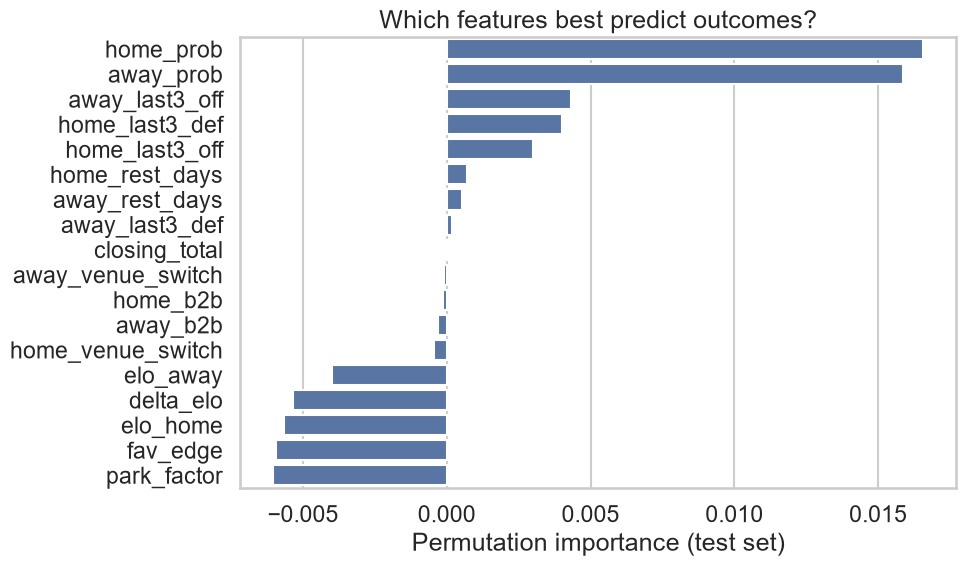

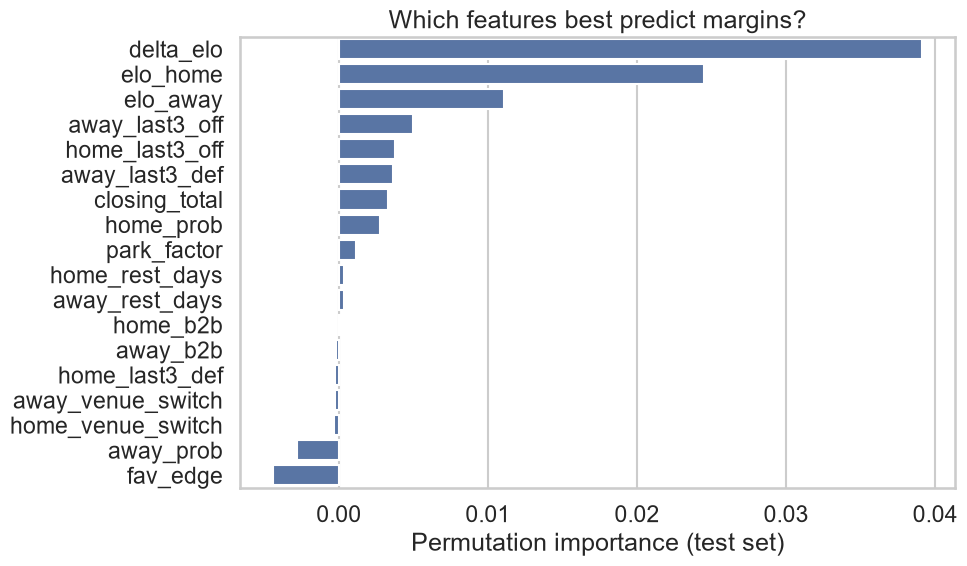

,feature,importance_mean,importance_std
0,home_prob,0.016578,0.006996
1,away_prob,0.015878,0.003780
16,away_last3_off,0.004319,0.003393
15,home_last3_def,0.003990,0.006378
14,home_last3_off,0.003003,0.002385
8,home_rest_days,0.000699,0.001930
9,away_rest_days,0.000535,0.001025
17,away_last3_def,0.000165,0.005890


In [8]:
def perm_importance(model, X, y):
    r = permutation_importance(model, X, y, n_repeats=10, random_state=0, n_jobs=-1)
    return (pd.DataFrame({'feature': features, 'importance_mean': r.importances_mean,
                          'importance_std': r.importances_std})
              .sort_values('importance_mean', ascending=False))

imp_cls = perm_importance(clf, Xte, yte_cls)
imp_reg = perm_importance(reg, Xte, yte_reg)

for imp, title, fname in [(imp_cls, "Which features best predict outcomes?", "importance_outcome.png"),
                          (imp_reg, "Which features best predict margins?", "importance_margin.png")]:
    plt.figure(figsize=(10,6))
    sns.barplot(data=imp, x="importance_mean", y="feature", orient="h")
    plt.title(title); plt.xlabel("Permutation importance (test set)"); plt.ylabel("")
    plt.tight_layout(); savefig(fname); plt.show()

imp_cls.head(8)

## 4. Q3 — Does the model beat simple baselines?

- **Dummy:** always predict the more common class in training (home win).
- **Market favorite:** pick the team the closing line favors; its probability is the vig-removed implied home-win probability.

In [9]:
dum = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr_cls)
dummy = dict(acc=dum.score(Xte, yte_cls))

market_p = np.clip(Xte["home_prob"].to_numpy(), 1e-6, 1 - 1e-6)   # P(home win) implied by the market
market = dict(acc=accuracy_score(yte_cls, market_p >= 0.5),
              logloss=log_loss(yte_cls, market_p), brier=brier_score_loss(yte_cls, market_p))

summary = pd.DataFrame({
    "Accuracy": [dummy['acc'], market['acc'], rf['acc']],
    "Log loss": [np.nan, market['logloss'], rf['logloss']],
    "Brier":    [np.nan, market['brier'], rf['brier']],
}, index=["Dummy (always home)", "Market favorite", "Random Forest"]).round(3)
summary

,Accuracy,Log loss,Brier
Dummy (always home),0.538,NaN,NaN
Market favorite,0.565,0.676,0.241
Random Forest,0.558,0.692,0.249


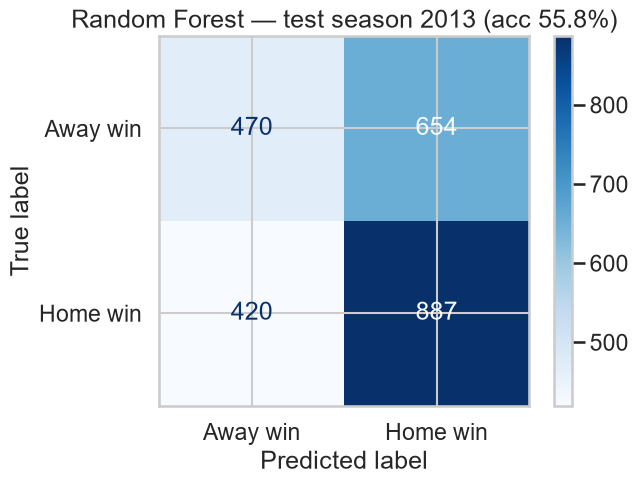

In [10]:
cm = confusion_matrix(yte_cls, (p >= 0.5).astype(int), labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Away win", "Home win"]).plot(cmap="Blues", values_format="d")
plt.title(f"Random Forest — test season {test_seasons[0]} (acc {rf['acc']:.1%})")
savefig("confusion_matrix.png"); plt.show()

### Robustness: hold out each season in turn

A single held-out season is a small sample. Repeating the comparison with each of the five seasons as the test set shows whether the result depends on which season was held out.

In [11]:
rows = []
for s in sorted(set(seasons)):
    tr, te = seasons != s, seasons == s
    m = RandomForestClassifier(n_estimators=400, random_state=0, n_jobs=-1).fit(X[tr], y_cls[tr])
    p_s = m.predict_proba(X[te])[:, 1]
    mk = np.clip(X.loc[te, "home_prob"].to_numpy(), 1e-6, 1 - 1e-6)
    rows.append({"test_season": int(s), "games": int(te.sum()),
                 "rf_acc": accuracy_score(y_cls[te], p_s >= 0.5), "market_acc": accuracy_score(y_cls[te], mk >= 0.5),
                 "rf_logloss": log_loss(y_cls[te], p_s), "market_logloss": log_loss(y_cls[te], mk)})
loso = pd.DataFrame(rows).round(3)
loso.to_csv(RESULTS / "leave_one_season_out.csv", index=False)
loso

,test_season,games,rf_acc,market_acc,rf_logloss,market_logloss
0,2012,2430,0.544,0.579,0.697,0.676
1,2013,2431,0.558,0.565,0.692,0.676
2,2014,2430,0.545,0.570,0.691,0.677
3,2015,2429,0.548,0.578,0.688,0.676
4,2016,2426,0.566,0.581,0.689,0.673


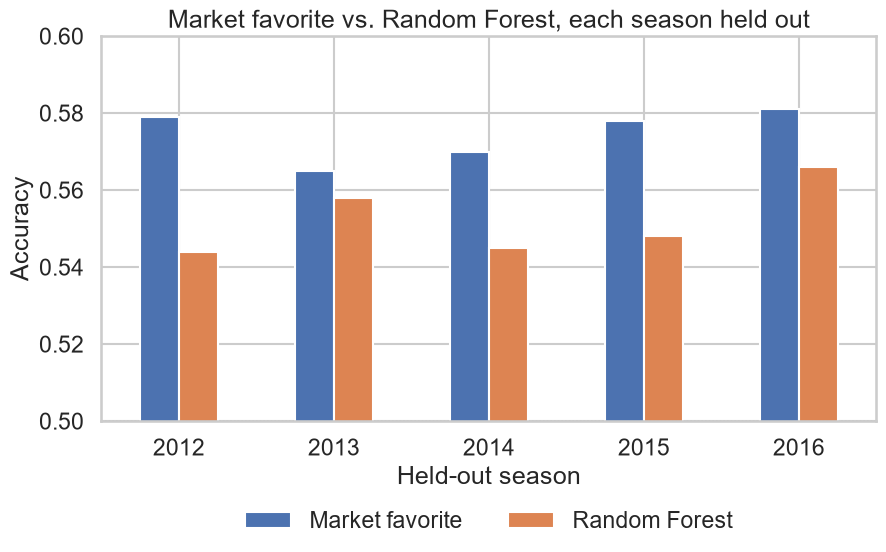

In [12]:
ax = loso.set_index("test_season")[["market_acc", "rf_acc"]].rename(
    columns={"market_acc": "Market favorite", "rf_acc": "Random Forest"}).plot.bar(figsize=(10, 5), rot=0)
ax.axhline(0.5, color="grey", lw=1, ls=":")
ax.set_ylim(0.5, 0.6); ax.set_xlabel("Held-out season"); ax.set_ylabel("Accuracy")
ax.set_title("Market favorite vs. Random Forest, each season held out")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
savefig("market_vs_model_by_season.png"); plt.show()

In [13]:
metrics = {
    "games_modeled": int(len(dm)), "train_rows": int(len(Xtr)), "test_rows": int(len(Xte)),
    "test_seasons": [int(s) for s in test_seasons],
    "q1": {"pct_one_run": round(float(p_le1), 3), "pct_two_plus": round(float(p_ge2), 3),
           "margin_r2": round(float(lin.score(X_lin, y_lin)), 3)},
    "classification": {k: {m: round(float(v), 3) for m, v in d.items()}
                       for k, d in {"dummy": dummy, "market_favorite": market, "random_forest": rf}.items()},
    "margin_regression": {m: round(float(v), 3) for m, v in rf_reg.items()},
    "top_outcome_features": imp_cls['feature'].head(5).tolist(),
    "leave_one_season_out": {"market_wins_acc": int((loso.market_acc > loso.rf_acc).sum()),
                             "market_wins_logloss": int((loso.market_logloss < loso.rf_logloss).sum()),
                             "seasons": int(len(loso))},
}
(RESULTS / "metrics.json").write_text(json.dumps(metrics, indent=2))
metrics["classification"]

{'dummy': {'acc': 0.538},
 'market_favorite': {'acc': 0.565, 'logloss': 0.676, 'brier': 0.241},
 'random_forest': {'acc': 0.558, 'logloss': 0.692, 'brier': 0.249}}

## Takeaways

- About 70% of games are decided by 2+ runs, so ±1.5 splits outcomes cleanly; closing total and favorite strength explain under 1% of the variation in margin (R² ≈ 0.005).
- For predicting the winner, the market's implied probabilities carry almost all of the signal. Elo, rest and recent-form features add little on top of the closing line.
- On the held-out 2013 season, the Random Forest (55.8%) does **not** beat simply backing the market favorite (56.5%), and the market's probabilities are better calibrated (log loss 0.676 vs 0.692). The closing line already prices in the public information these features capture — consistent with an efficient betting market.
- Holding out each of the five seasons in turn gives the same answer every time: the market favorite beats the Random Forest on both accuracy and log loss in all 5 seasons.
- Score margins are not predictable from these features (Random Forest regressor R² < 0).